# 02 · Docker


## 本章来源与学习路线

本篇对应百度网盘 **`我的资源/day02-Docker/PPT/Docker.pptx»**，共 **53 页，无隐藏页**。已同时读取 `PPT/mysql-init.txt» 和 `资料/docker-compose.yml»，并查看配套资料目录。整理日期：2026-10-09。

课件预览：[Docker](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday02-Docker%2FPPT%2FDocker.pptx&fsid=1078521167656547&size=1159108&view_from=personal_file&md5=dca7c9af9l9cd2e1e7f185b68a908eda&share=0&client=web&scene=main)。

| 阶段 | 课件页码 | 学习目标 |
| --- | --- | --- |
| 快速入门 | 1—19 | 理解镜像、容器、仓库，运行 MySQL |
| Docker 基础 | 20—42 | 操作容器、保存数据、构建镜像、连接网络 |
| 项目部署 | 43—53 | 部署 hmall、Nginx，并用 Compose 统一管理 |

配套目录包含 `demo»、`hmall»、`mysql»、`nginx»、`images»、系统安装镜像、日志清理脚本和 Compose 文件。正文以课件、已读的启动文本和 Compose 配置为依据，**未完整读取或运行 hmall 源码及其全部配置**。

**阅读约定**：标注“课件方案”的内容保留原课思路；“整理示例”补全代码和命令；“补充/改进”解释实际部署边界。命令默认在安装好 Docker Engine 与 Compose 插件的 **Linux 主机 / Bash** 中执行，`\» 用于 Bash 续行，行尾不能再有空格。Windows PowerShell 的续行语法不同，不能直接按这些反斜杠换行粘贴。

课件出现 CentOS 7、Ubuntu 16.04、JDK 8、`openjdk:11.0-jre-buster» 等历史环境。笔记用 Java 11 整理应用镜像示例，实际部署应按项目兼容性选择仍受维护的系统和镜像。所有命令均为学习示例，本篇没有在本机执行容器部署。


## 1. Docker 解决的部署问题

传统部署要逐台安装软件、依赖库和运行环境，安装顺序、版本或配置稍有差异就可能出错。课件第 2—6 页用安装 MySQL 的多条 RPM 命令与 `docker run» 对比，说明部署过程可以被标准化。

**Docker 是构建、分发、运行和管理容器应用的工具。** 开发者把应用及用户空间依赖打成镜像，部署者根据镜像创建容器，再提供环境变量、网络和持久化存储。

| 环节 | Docker 中的对应物 |
| --- | --- |
| 准备应用及运行依赖 | 构建镜像 |
| 分发可部署的软件包 | 推送、拉取镜像 |
| 启动隔离的应用实例 | 创建容器 |
| 管理运行与日志 | start、stop、logs、exec |
| 保留业务数据 | 数据卷或目录挂载 |
| 统一部署多个组件 | Docker Compose |

镜像减少环境差异，但数据库数据、外部配置、权限、网络和宿主机资源仍需管理。课件中的卸载数据库和 `rpm -e --nodeps» 是传统安装背景，不是运行 Docker 的通用前置步骤；应先检查实际端口和软件依赖。


## 2. 镜像、容器、仓库与 Docker 架构

要读懂 Docker 命令，先区分“应用模板”和“运行实例”。（课件第 14—15 页）

| 概念 | 含义 | 示例 |
| --- | --- | --- |
| 镜像 Image | 应用及其运行依赖、配置、启动元信息组成的只读模板 | `mysql:8.0» |
| 容器 Container | 根据镜像创建的隔离运行实例，带自己的可写层 | `mysql-demo» |
| 镜像仓库 Registry | 存储并分发镜像的服务 | Docker Hub、企业私有仓库 |
| Docker Client | 接收命令的客户端 | `docker run» |
| Docker daemon | 执行构建、拉取、启动等操作的守护进程 | `dockerd» |
| 宿主机 Host | 提供内核、存储、CPU 和内存的机器 | Linux 服务器 |

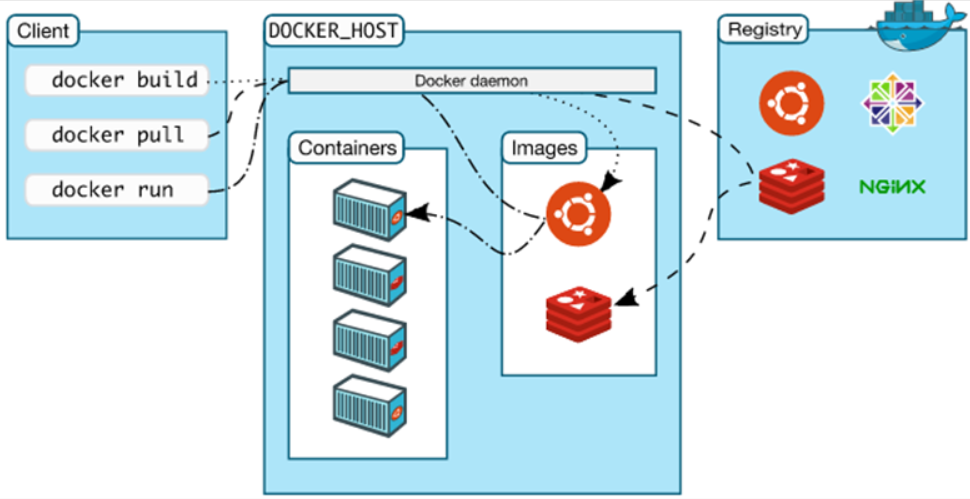

```text
Docker Client
    │ 请求
    ▼
Docker daemon ── 拉取 / 推送 ── 镜像仓库
    │
    ├── 管理本地镜像
    └── 根据镜像创建多个容器
```

一个镜像可以创建多个容器，它们的运行状态和可写层彼此独立。删除某个容器不等于删除镜像，下载一个镜像也不等于已经启动应用。

**补充**：普通 Linux 容器共享宿主机内核，利用命名空间隔离进程、网络等视图，利用 cgroups 控制资源。镜像内的 Ubuntu 等内容主要提供用户空间文件，不会为每个容器启动一套独立内核。

| 比较项 | 普通 Linux 容器 | 虚拟机 |
| --- | --- | --- |
| 内核 | 共享宿主机内核 | 每台虚拟机有自己的内核 |
| 隔离对象 | 进程及相关资源视图 | 完整客体操作系统 |
| 启动开销 | 通常较小 | 通常较大 |
| 系统兼容 | 需匹配内核、架构等条件 | 通过虚拟硬件运行客体系统 |

Docker Desktop 在 Windows、macOS 上运行 Linux 容器时通常借助 Linux 虚拟化环境，因此容器里的 Linux 路径并不等于 Windows 的 `C:\» 目录。


## 3. 环境检查与第一个 MySQL 容器

课件第 13 页的前提是已经安装 Docker、网络可用，且宿主机 3306 端口没有被其他服务占用。先验证环境，再理解启动命令。

```bash
docker version
docker info
docker compose version
```

`docker version» 应能看到 Client 与 Server 信息。只有客户端信息、提示无法连接 daemon 时，应先检查 Docker 服务或当前连接目标，不能把它误判成镜像问题。

**整理示例**：`mysql:8.0» 用作课程兼容示例标签，实际版本需按项目验证；密码由当前终端环境提供。

```bash
export MYSQL_IMAGE='mysql:8.0'
read -r -s -p 'MySQL root password: ' MYSQL_ROOT_PASSWORD
echo
export MYSQL_ROOT_PASSWORD

docker run -d \
  --name mysql-demo \
  -p 127.0.0.1:3306:3306 \
  -e TZ=Asia/Shanghai \
  -e MYSQL_ROOT_PASSWORD \
  "$MYSQL_IMAGE"

docker ps
docker logs --tail 100 mysql-demo
```

示例将数据库端口绑定到宿主机回环地址，供本机访问。课件使用 `-p 3306:3306»，通常发布到宿主机所有接口；如果通过另一台电脑连接虚拟机中的数据库，应使用可达的宿主机地址及经过配置的监听地址、端口和防火墙规则。

`PPT/mysql-init.txt» 实际是课件的 MySQL **启动命令**，没有 SQL 建表内容。它省略了镜像标签并使用演示密码，整理示例改为显式标签和环境输入。

> 这里只演示启动，尚未配置可识别、可迁移的持久化目录。数据库长期使用时应按后文挂载数据。容器创建成功也不代表 MySQL 已经完成初始化，应查看日志或就绪状态。


## 4. docker run 参数与端口映射

`docker run» 会根据镜像 **创建并启动一个新容器**。本地没有所需镜像时，通常会按拉取策略尝试获取。（课件第 17—19 页）

```text
docker run [Docker选项] 镜像名[:标签] [容器内命令及参数]
```

| 参数 | 含义 | 判断重点 |
| --- | --- | --- |
| `-d» | 后台运行 | 不会自动让已退出的应用继续运行 |
| `--name mysql-demo» | 指定容器名称 | 同一 daemon 下名称需要唯一，停止的容器仍占名 |
| `-p 3307:3306» | 宿主机端口映射到容器端口 | 左边宿主机，右边容器 |
| `-e TZ=Asia/Shanghai» | 设置容器环境变量 | 镜像或应用必须支持读取该变量 |
| `-e MYSQL_ROOT_PASSWORD» | 从当前终端环境取同名变量 | 需要先设置或导出变量 |
| `-v ...:... » | 挂载存储 | 区分数据卷名与主机路径 |
| `--network hm-net» | 接入指定网络 | 网络需要已存在，Compose 可代建 |

```text
外部客户端
    ↓ 宿主机IP:3307
宿主机发布端口 3307
    ↓ 映射
MySQL 容器内端口 3306
```

在外部电脑访问 `宿主机IP:3307»，在同一 Docker 网络中的另一个容器访问 `mysql-demo:3306»。内部访问不使用宿主机映射端口 3307。

**命令顺序修正**：Docker 参数应放在镜像名之前。

```bash
# 正确：-p 是 docker run 参数
docker run -d --name nginx-demo -p 8081:80 nginx:stable

# 不符合本例意图：镜像名后面的 -p 会被当作容器命令参数
# docker run -d --name nginx-demo nginx:stable -p 8081:80
```

`EXPOSE» 和 `-p» 的区别在后文 Dockerfile 中说明。端口映射不会自动修改应用监听端口，也不会自动把两个容器接入同一个自定义网络。


## 5. 镜像名称、标签与版本选择

镜像名称决定从哪里取哪个应用版本。（课件第 18 页）

```text
[registry/][namespace/]repository[:tag]
例如：mysql:8.0
      nginx:stable
      registry.example.com/team/hmall:1.0
```

| 部分 | 含义 |
| --- | --- |
| registry | 仓库服务地址，省略时通常使用 Docker Hub |
| namespace | 用户或组织命名空间 |
| repository | 镜像仓库名称，仓库路径通常要求小写 |
| tag | 某个镜像版本或用途的标签 |

没有 tag 时通常使用 `latest»。**`latest» 只是默认标签，不保证是最新发布时间、最新大版本或项目兼容版本**；本地已有镜像时，普通启动也不保证自动更新到远端最新内容。

`mysql:8.0» 固定了版本系列，但标签仍可能指向更新后的镜像。需要可复现部署时，可进一步选定完整版本或镜像摘要 `repository@sha256:... »，并记录验证结果。

课件中不带 tag 的 `mysql»、`nginx» 适合讲解命令格式。笔记中的 `mysql:8.0» 是兼容课程的示例，`nginx:stable» 和 `eclipse-temurin:11-jre» 也是可变标签，不应被当成永久不变的构建结果。


## 6. 镜像与容器的常见命令

镜像用于分发和创建实例，容器用于运行应用。先确认操作对象，再选择命令。（课件第 22—23 页）

| 对象 | 命令 | 用途 |
| --- | --- | --- |
| 镜像 | `docker pull nginx:stable» | 拉取镜像 |
| 镜像 | `docker images» | 查看本地镜像 |
| 镜像 | `docker build -t hmall:1.0 .» | 构建镜像 |
| 镜像 | `docker push 仓库/镜像:标签» | 推送镜像，需要目标仓库权限 |
| 镜像 | `docker save -o nginx.tar nginx:stable» | 将镜像保存为归档 |
| 镜像 | `docker load -i nginx.tar» | 从归档加载镜像 |
| 镜像 | `docker rmi nginx:stable» | 删除本地镜像或标签 |
| 容器 | `docker run ...» | 创建并启动新容器 |
| 容器 | `docker ps» / `docker ps -a» | 查看运行中 / 全部容器 |
| 容器 | `docker stop nginx-demo» | 停止容器 |
| 容器 | `docker start nginx-demo» | 启动已有的停止容器 |
| 容器 | `docker restart nginx-demo» | 重启已有容器 |
| 容器 | `docker logs -f --tail 100 nginx-demo» | 跟随查看标准输出日志 |
| 容器 | `docker exec -it nginx-demo sh» | 在运行中的容器执行 shell |
| 容器 | `docker inspect nginx-demo» | 查看配置、挂载和网络等详情 |
| 容器 | `docker rm nginx-demo» | 删除已停止容器 |

`save/load» 保存和加载的是镜像，不会自动备份运行中数据库的数据卷。`push» 上传的是镜像层，也不包含外置挂载目录中的数据。

```text
镜像 ── run ──► 新容器（运行中）
                  │ stop
                  ▼
                已停止
                  │ start
                  └────────► 运行中

已停止容器 ── rm ──► 容器移除
```

重复执行同名 `run» 不会复用已有容器，通常报名称冲突。要恢复原实例用 `start»；要应用新镜像或新挂载配置，一般需要重新创建。


## 7. Nginx 入门练习与容器生命周期

课件第 23、25 页要求拉取 Nginx、启动、停止、进入容器并修改静态页面。这能同时验证镜像、容器和端口映射。

**整理示例**，假设 `nginx-demo» 尚未存在：

```bash
docker pull nginx:stable
docker images
docker run -d --name nginx-demo -p 8081:80 nginx:stable
docker ps
curl http://127.0.0.1:8081

docker stop nginx-demo
docker ps -a
docker start nginx-demo
docker exec -it nginx-demo sh
```

进入后可查看 `/usr/share/nginx/html/index.html»，使用 `exit» 退出 shell。镜像不一定安装了 `bash»、`vim»、`curl» 等工具，命令不存在不代表容器损坏；最小镜像可能连 shell 都没有。

| 现象 | 原因或含义 |
| --- | --- |
| `-d» 后立刻变成 Exited | 主进程退出或启动失败，优先查看日志 |
| 退出 `docker exec» 的 shell | 只结束本次附加进程，通常不结束原应用 |
| 停止再启动后文件修改仍在 | 复用了同一容器的可写层 |
| 删除并重建后修改丢失 | 修改仅保存在旧容器的可写层 |

容器通常随其主进程结束而停止。用于服务的进程需要在容器前台持续运行，例如官方 Nginx 镜像已经配置了合适的启动命令。

直接进入容器改文件适合观察机制。要稳定部署页面和配置，应使用后文挂载或构建镜像保存修改。


## 8. 持久化存储：可写层、数据卷与目录挂载

容器需要能随时替换，而数据库数据和站点资源需要保留。把需要长期保存的目录放到容器之外，可以让容器重建与数据生命周期分开。（课件第 26—30 页）

| 存储方式 | 数据位置与管理方式 | 容器删除后 |
| --- | --- | --- |
| 容器可写层 | 当前容器的内部文件变更 | 随容器移除 |
| 命名数据卷 Volume | Docker 管理的存储目录，以名称引用 | 通常保留，除非显式删除卷 |
| 绑定挂载 Bind mount | 直接使用指定宿主机路径 | 主机文件通常保留 |

```text
宿主机存储                          容器内部路径

命名卷 html ──────────────────► /usr/share/nginx/html

/root/mysql/data ──────────────► /var/lib/mysql
主机明确路径                         MySQL数据目录
```

课件把数据卷称为容器目录与宿主机目录的“桥梁”。更准确地说，命名卷由 Docker 管理具体存储位置；绑定挂载则由使用者指定主机路径。

| `-v» 写法 | Docker 的解释 |
| --- | --- |
| `-v html:/usr/share/nginx/html» | 名为 html 的数据卷 |
| `-v /root/site:/usr/share/nginx/html» | 宿主机绝对路径绑定挂载 |
| `-v ./site:/usr/share/nginx/html» | 支持该写法的环境中，当前目录下的 site |
| `-v mysql:/var/lib/mysql» | 名为 mysql 的卷，不是当前目录的 mysql 文件夹 |

Linux 示例优先使用明确绝对路径或 `"$PWD/site"»。远程 Docker 的绑定源路径位于 **daemon 所在主机**；Docker Desktop 则要符合其目录共享和路径转换规则。

**两个容易混淆的行为**：空的新数据卷挂到镜像已有文件的目录时，Docker 通常会复制原目录内容到卷中；绑定一个空主机目录时，通常只是遮住镜像中的原内容，不会自动把默认首页复制出来。


## 9. 数据卷命令与 Nginx 页面挂载

命名卷方便通过名称管理，不必把宿主机内部存储路径写死。（课件第 27—29 页）

| 命令 | 用途 |
| --- | --- |
| `docker volume create html» | 创建命名卷 |
| `docker volume ls» | 查看数据卷 |
| `docker volume inspect html» | 查看驱动、挂载位置等详情 |
| `docker volume rm html» | 删除指定且未被占用的数据卷 |
| `docker volume prune» | 按当前版本规则清理未使用卷 |

课件展示常见本地存储位置 `/var/lib/docker/volumes/卷名/_data»。实际位置会受到 data-root、rootless、驱动和 Docker Desktop 等因素影响，应以 `volume inspect» 为准。

**课件命名卷方案整理**：

```bash
docker volume create html
docker run -d \
  --name nginx-volume \
  -p 8082:80 \
  -v html:/usr/share/nginx/html \
  nginx:stable

docker volume inspect html
docker inspect nginx-volume
```

命名卷不存在时，`run -v 卷名:目标路径» 通常自动创建。编辑或导入卷里的页面后访问宿主机 8082 端口验证。

**整理示例：将自己的站点目录直接挂入容器**：

```bash
mkdir -p site
printf '%s\n' '<h1>Hello Docker</h1>' > site/index.html
docker run -d \
  --name nginx-site \
  -p 8083:80 \
  --mount "type=bind,source=$PWD/site,target=/usr/share/nginx/html,readonly" \
  nginx:stable
```

只读挂载 `readonly» 让容器读取站点资源，同时由宿主机管理文件。需要容器写入的数据库目录则不能照搬只读设置。

> 清理卷会删除其中的数据。不同 Docker 版本的 `volume prune» 对匿名卷、命名卷的默认范围可能不同，先查看 `docker volume prune --help»；`未被容器引用» 也不代表业务数据已经不需要。


## 10. MySQL 的数据、配置与初始化脚本挂载

课件第 30 页把 MySQL 拆成三类目录，避免容器删除后数据丢失，也让配置与初始化脚本可管理。

**先检查现有挂载**：官方 MySQL 镜像通常为 `/var/lib/mysql` 声明 VOLUME，即使最初 `run` 没写 `-v`，也可能自动产生匿名卷。匿名卷使用自动生成的名称，不便直接关联业务和迁移；应查看 `docker inspect 容器名` 中的 Mounts，不能把“没写 -v”等同于“一定没有挂载”。本节改用明确的主机目录管理数据。

| 宿主机目录 | 容器目录 | 内容 |
| --- | --- | --- |
| `/root/mysql/data» | `/var/lib/mysql» | 数据文件，需要读写 |
| `/root/mysql/conf» | `/etc/mysql/conf.d» | 镜像支持的额外 MySQL 配置 |
| `/root/mysql/init» | `/docker-entrypoint-initdb.d» | 首次初始化时执行的 SQL / 脚本 |

**整理示例**：先准备配置和初始化文件，再创建一个使用独立名称的容器。

```bash
mkdir -p /root/mysql/data /root/mysql/conf /root/mysql/init

docker run -d \
  --name mysql-persist \
  -p 127.0.0.1:3307:3306 \
  -e TZ=Asia/Shanghai \
  -e MYSQL_ROOT_PASSWORD \
  --mount type=bind,source=/root/mysql/data,target=/var/lib/mysql \
  --mount type=bind,source=/root/mysql/conf,target=/etc/mysql/conf.d,readonly \
  --mount type=bind,source=/root/mysql/init,target=/docker-entrypoint-initdb.d,readonly \
  "$MYSQL_IMAGE"

docker inspect mysql-persist
docker logs --tail 100 mysql-persist
```

示例复用前面设置的环境变量。容器配置目录依镜像发行变体而定，实际使用时核对所选标签的官方说明；Java、MySQL 镜像与挂载配置应一起验证。

**首次初始化规则**：

| 场景 | 预期行为 |
| --- | --- |
| 数据目录为空，第一次启动 | 官方镜像初始化数据库，并执行支持的初始化脚本 |
| 数据目录已有数据库，重建同版本容器 | 通常直接使用已有数据，不重复执行初始化脚本 |
| 修改初始化 SQL 后重启已有数据库 | 不会自动完成数据库迁移 |
| 修改 `MYSQL_ROOT_PASSWORD» 后复用旧数据 | 不会自动重设数据库里的已有密码 |

初始化 SQL 应安排依赖顺序，必要时使用有序文件名，例如 `01-schema.sql»、`02-data.sql»。上线后的变更需要数据库迁移方案。

挂载数据目录不会自动成为数据库备份。运行中的文件可能处于不一致状态，迁移应采用合适的逻辑备份、物理备份或受控停机流程；不能把直接复制活动数据目录当成可靠备份。


## 11. 目录与文件挂载的常见边界

数据库和 Nginx 都需要挂载配置，错误通常来自路径层次、文件类型或权限。

| 错误 | 表现 | 判断方式 |
| --- | --- | --- |
| 把卷名当主机目录 | 主机预期位置没有数据 | 检查 `inspect» 中 Mounts 的 Type、Source、Destination |
| 文件路径不存在 | `-v» 短语法可能创建成目录，随后挂载报错 | 提前验证文件存在，文件挂载可用 `--mount» |
| 空目录遮住镜像文件 | 默认首页或配置“消失” | 区分绑定挂载与新卷内容初始化 |
| 配置没有被读取 | 改了文件但应用行为不变 | 核对容器路径、主配置的 include 规则、是否需重载 |
| 写入失败 | Permission denied | 核对容器运行用户、主机属主、权限和系统安全策略 |

**文件挂载整理示例**：

```bash
test -f "$PWD/nginx/nginx.conf"
docker run -d \
  --name nginx-config-demo \
  -p 8084:80 \
  --mount "type=bind,source=$PWD/nginx/nginx.conf,target=/etc/nginx/nginx.conf,readonly" \
  nginx:stable
```

这个命令要求配置确实监听容器 80 端口。后文商城示例监听 18080、18081，不能原样套用这里的 `8084:80»。

把整个 `nginx.conf» 挂到主配置位置时，文件需要包含相应的完整结构；只有一个 `server { ... }» 片段时，应放在被主配置 include 的位置，而不是随意覆盖整个主配置。


## 12. 自定义镜像与分层结构

通用 MySQL、Nginx 可以直接使用现成镜像，自研 Java 应用需要把运行环境与 Jar 包组合成自己的镜像。（课件第 32—34 页）

| 传统 Java 部署步骤 | 镜像构建对应步骤 |
| --- | --- |
| 准备 Linux 环境 | 选择基础镜像 |
| 安装 JRE 并设置环境变量 | 使用已有 Java 运行时镜像，或自行安装 |
| 上传 Jar | COPY 到镜像内部 |
| 执行 `java -jar» | 配置 ENTRYPOINT / CMD |

JRE 是运行 Java 应用所需的运行环境，JDK 还包含编译等开发工具。已经编译好的 Jar 通常只需兼容的运行环境。

```text
镜像层（只读，共享）
  基础系统用户空间文件
  + Java运行时
  + 应用Jar及必要文件
  + 启动配置
          ↓ 创建容器
容器自己的可写层
          + 外置挂载的数据或配置
```

分层让不同镜像复用公共内容，也支持构建缓存。课件把每次操作概括为“形成一层”，应区分文件系统层与镜像元信息：`RUN»、`COPY» 等可产生文件变更层；`ENV»、`EXPOSE»、启动命令等主要设置元信息，不一定增加新的文件系统层。

把数据库数据复制进应用镜像会让镜像和动态数据耦合；本课更合理的结构是应用镜像可替换，MySQL 数据通过挂载保留。


## 13. Dockerfile 指令

Dockerfile 用固定指令描述镜像如何构建，Docker 按文件和构建上下文生成镜像。（课件第 35—39 页）

| 指令 | 用途 | 整理示例 |
| --- | --- | --- |
| `FROM» | 指定基础镜像 | `FROM eclipse-temurin:11-jre» |
| `ENV» | 设置镜像默认环境变量 | `ENV TZ=Asia/Shanghai» |
| `WORKDIR» | 设置后续工作目录 | `WORKDIR /app» |
| `COPY» | 从构建上下文复制文件 | `COPY hmall.jar app.jar» |
| `RUN» | 构建时执行命令 | 安装依赖、准备目录 |
| `EXPOSE» | 声明应用预期端口 | `EXPOSE 8080» |
| `ENTRYPOINT» | 容器启动时执行的主命令 | `["java","-jar","/app/app.jar"]» |
| `CMD» | 提供默认命令或默认参数 | 可被运行时参数覆盖 |

**构建时与运行时**：

| 写法 | 什么时候发生 | 适合做什么 |
| --- | --- | --- |
| `RUN ...» | `docker build» 时 | 安装软件、准备镜像文件 |
| `ENTRYPOINT ...» | 容器启动时 | 运行 Java 服务 |
| `docker run -e ...» | 容器创建时 | 注入该实例的配置 |

`EXPOSE 8080» 不会启动应用，也不会把 8080 发布到宿主机。应用需要真的监听 8080，外部访问还需 `-p 宿主机端口:8080»。

**补充**：推荐使用 JSON 数组形式的 ENTRYPOINT，使 Java 进程直接接收停止信号。数组形式不会自动进行 shell 变量展开，`["java","-jar","$JAR_PATH"]» 不会像 Bash 一样替换变量；需要按具体启动方式设计。


## 14. Java 应用镜像与课件示例修正

课件先演示在 Ubuntu 中安装 JDK，再演示直接使用 Java 基础镜像。实际项目通常选用已准备好兼容运行时的基础镜像，减少安装步骤。（课件第 36—38 页）

**整理示例**：基础镜像的 Java 11 标签需按实际项目与维护策略验证。

```dockerfile
FROM eclipse-temurin:11-jre
WORKDIR /app
ENV TZ=Asia/Shanghai
COPY docker-demo.jar app.jar
EXPOSE 8080
ENTRYPOINT ["java", "-jar", "/app/app.jar"]
```

Jar 的编译目标和运行时要匹配。Java 17 编译的程序通常不能直接在 Java 11 运行时执行。

| 课件细节 | 需要修正或理解的地方 |
| --- | --- |
| 复制 Jar 到 `/tmp/app.jar»，入口却是 `/app.jar» | 目标路径必须一致，否则无法找到 Jar |
| `RUN» 示例中的 `EXPORTS» | 不是正确的 shell 环境变量设置命令 |
| 只在某个 RUN 中 `export PATH=... » | 不会自动持久化为后续容器环境，应使用 ENV |
| 早期 Ubuntu / OpenJDK 标签 | 保留历史背景，当前构建需重新核对镜像可用性和维护状态 |
| `docker build -t myImage:1.0 .» | 仓库名应小写，例如 `myimage:1.0» |

```bash
docker build -t docker-demo:1.0 .
docker run -d \
  --name docker-demo \
  -p 8085:8080 \
  docker-demo:1.0
docker logs --tail 100 docker-demo
```

这个示例假设 Jar 实际监听 8080；端口不同应同步调整。镜像构建成功只说明构建步骤完成，不能代替启动和接口验证。


## 15. 构建上下文与缓存

COPY 能看到哪些文件，取决于构建上下文，而不是当前 Dockerfile 写在哪个文件夹。这是课件第 38—39 页命令说明需要补充的关键区别。

```bash
docker build -t hmall:1.0 .
docker build -f docker/Dockerfile -t hmall:1.0 .
```

| 参数 | 实际含义 |
| --- | --- |
| `-t hmall:1.0» | 为构建结果指定镜像名和标签 |
| `-f docker/Dockerfile» | 指定使用的 Dockerfile 文件 |
| 末尾 `.» | 将当前目录作为构建上下文 |

不写 `-f» 时，通常使用上下文根目录中的 `Dockerfile»。课件把最后的目录简化成“Dockerfile 所在目录”；两者在默认布局下可能相同，但概念不能混为一谈。

```text
deploy/                 ← 构建上下文
├── Dockerfile
├── hmall.jar            ← COPY可见
├── .dockerignore
├── mysql/
└── nginx/
```

COPY 源路径按上下文解析，不能随意用 `../» 复制上下文外的文件。发送大量无关文件会拖慢构建，可以设置：

```text
# .dockerignore 整理示例
.git
.env
mysql/
nginx/
**/target/
```

本例假设已将打包好的 `hmall.jar» 放在上下文根目录，所以忽略源码构建目录不会排除这个 Jar。若改为从 `target/» COPY，忽略规则也要同步调整。

较稳定的步骤放前面，经常变化的应用文件放后面，有助于复用缓存。修改 Jar 后需要重新构建并用新镜像重建容器；单纯 `docker restart» 不会重新执行 Dockerfile。


## 16. 容器网络与访问地址

多个容器需要通信，不能把宿主机地址、容器地址和 `localhost» 混为一谈。（课件第 41—42 页）

Linux Docker Engine 通常把未指定网络的容器接入默认 `bridge» 网络，通过虚拟网桥连接。课件图中的 `docker0»、`172.17.0.x» 是示意，实际网段由环境决定。

```text
自定义网络 hmall
┌────────────────────────────────────────────┐
│ Nginx            Java hmall        MySQL   │
│ nginx ─────────► hmall:8080 ──────► mysql:3306
└────────────────────────────────────────────┘
        ▲
        │ 宿主机发布端口18080 / 18081
        │
      浏览器
```

| 发起访问的位置 | 应使用的地址 |
| --- | --- |
| 宿主机上的客户端 | `127.0.0.1:已发布端口» |
| 另一台电脑的浏览器 | `Docker宿主机可达IP:已发布端口» |
| 同一自定义网络中的 Nginx | `hmall:8080» |
| 同一自定义网络中的 Java | `mysql:3306»，或实际数据库容器名 / 网络别名 |
| Java 容器中的 `localhost» | Java 容器自身，不是 MySQL 容器 |

用户自定义 bridge 网络提供容器名 / 网络别名解析。默认 bridge 通常不提供同样的自动名称解析体验，课件因此要求创建自定义网络。容器 IP 会随重建变化，配置应优先使用网络中的名称。

> `mysql:3306» 这类名称由容器网络解析，普通外部浏览器通常不能解析。前端 JavaScript 在浏览器中执行，应请求浏览器可访问的地址，例如同源 `/api/»，再由 Nginx 转发到内部容器。

端口发布与容器间通信是两件事：共享网络中的服务通常直接使用内部端口，不必为每个服务都发布宿主机端口。


## 17. 自定义网络的管理

把相关服务接入同一个网络，再通过稳定名称通信。（课件第 42 页）

| 命令 | 用途 |
| --- | --- |
| `docker network create hmall» | 创建自定义网络 |
| `docker network ls» | 查看网络 |
| `docker network inspect hmall» | 查看成员与网络配置 |
| `docker network connect hmall mysql-persist» | 把已有容器接入网络 |
| `docker network disconnect hmall mysql-persist» | 让容器离开网络 |
| `docker network rm hmall» | 删除指定且不再占用的网络 |
| `docker network prune» | 清理满足条件的未使用网络 |

**整理示例**，承接前面的 `mysql-persist»：

```bash
docker network create hmall
docker network connect hmall mysql-persist
docker network inspect hmall
```

新容器在创建时使用 `--network hmall»，已有容器使用 `network connect»。如果网络已经存在，不必反复创建；应检查网络成员是否正确。

排查通信按“名称解析 → 目标端口监听 → 应用协议和认证”的顺序进行。能 ping 通不代表数据库认证成功；镜像里没有 ping 也不代表网络不通。


## 18. hmall Java 后端部署

课件第 45 页要求将资料中的 hmall 项目打包为镜像并部署。部署应同时解决应用包、数据库地址、网络和端口问题。

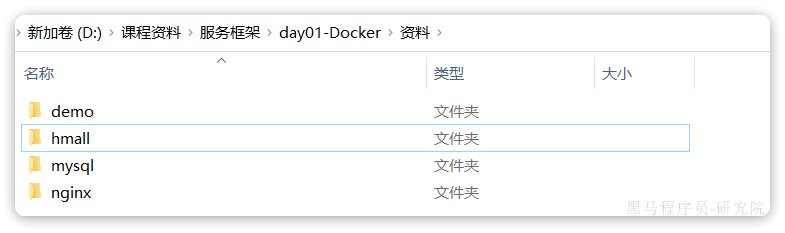

**整理流程**：

1. 按工程自己的构建方式生成可执行 Jar，并验证所需 Java 版本。
2. 把 Jar 统一命名为 `hmall.jar»，放到部署构建上下文。
3. 准备 MySQL 的 hmall 数据库及课前初始化数据。
4. 构建后端镜像，注入可用的数据源配置并接入同一网络。
5. 检查启动日志与实际业务接口。

**Dockerfile 整理示例**：

```dockerfile
FROM eclipse-temurin:11-jre
WORKDIR /app
ENV TZ=Asia/Shanghai
COPY hmall.jar app.jar
EXPOSE 8080
ENTRYPOINT ["java", "-jar", "/app/app.jar"]
```

**手动部署整理示例**，使用已连接 hmall 网络的 `mysql-persist»；当前终端先设置数据库用户名 `DB_USERNAME» 和密码 `DB_PASSWORD»：

```bash
docker build -t hmall:1.0 .
docker run -d \
  --name hmall \
  --network hmall \
  -p 127.0.0.1:8080:8080 \
  -e TZ=Asia/Shanghai \
  -e SPRING_DATASOURCE_URL='jdbc:mysql://mysql-persist:3306/hmall' \
  -e SPRING_DATASOURCE_USERNAME="${DB_USERNAME:?请先设置数据库用户名}" \
  -e SPRING_DATASOURCE_PASSWORD="${DB_PASSWORD:?请先设置数据库密码}" \
  hmall:1.0

docker logs -f --tail 100 hmall
```

这里使用 Spring Boot 标准数据源环境变量，属于整理方案；若工程有多数据源、自定义配置绑定或 profile，应核对实际生效配置。Jar 中监听端口不同也要同步调整。

| 常见错误 | 原因 |
| --- | --- |
| 数据库 URL 写 `localhost:3306» | Java 容器在连接自己 |
| URL 写宿主机发布端口 3307，但主机名是 `mysql-persist» | 容器名应配容器端口 3306 |
| 网络名相同但数据库没加入 | 创建网络不会自动连接已有容器 |
| 反复连接失败 | 还需检查数据库就绪、用户权限、密码和数据库名 |

手动部署与后文 Compose 是两种管理方式。学习时应选定一种接管同一组服务，避免已有 `hmall» 容器、相同端口或同名网络造成冲突。


## 19. Nginx 前端部署与反向代理

课件第 47 页要求挂载 `nginx.conf» 和 `html»，把前端资源交给 Nginx。Nginx 同时可以把浏览器的 API 请求转发给 Java 后端。

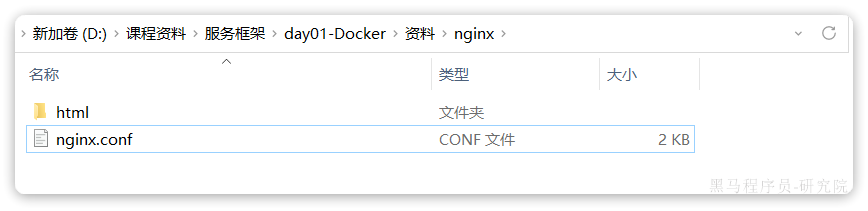

**整理示例目录**，实际目录名应与配套前端文件核对：

```text
nginx/
├── nginx.conf
└── html/
    ├── hmall/          # 商城前端构建产物
    │   └── index.html
    └── hmall-admin/    # 管理端构建产物
        └── index.html
```

**完整最小配置整理示例**，使用课件 Compose 中的 18080、18081 两个容器端口：

```nginx
events {
    worker_connections 1024;
}

http {
    include /etc/nginx/mime.types;
    default_type application/octet-stream;
    sendfile on;

    server {
        listen 18080;
        root /usr/share/nginx/html/hmall;
        index index.html;

        location /api/ {
            proxy_pass http://hmall:8080/;
            proxy_set_header Host $host;
            proxy_set_header X-Real-IP $remote_addr;
        }
        location / {
            try_files $uri $uri/ /index.html;
        }
    }

    server {
        listen 18081;
        root /usr/share/nginx/html/hmall-admin;
        index index.html;

        location /api/ {
            proxy_pass http://hmall:8080/;
            proxy_set_header Host $host;
            proxy_set_header X-Real-IP $remote_addr;
        }
        location / {
            try_files $uri $uri/ /index.html;
        }
    }
}
```

`try_files» 给单页应用提供前端路由回退，避免直接刷新前端路由时返回 404。API 匹配应由独立 `location /api/» 处理。

| 代理写法 | `/api/users» 转发到后端的路径 |
| --- | --- |
| `proxy_pass http://hmall:8080/;» | `/users» |
| `proxy_pass http://hmall:8080;» | `/api/users» |

整理示例按“后端路径不带 /api 前缀”书写；真实工程若保留该前缀，应调整，不能只看到 404 就改端口。

**容器启动整理示例**：

```bash
docker run -d \
  --name nginx \
  --network hmall \
  -p 18080:18080 \
  -p 18081:18081 \
  --mount "type=bind,source=$PWD/nginx/nginx.conf,target=/etc/nginx/nginx.conf,readonly" \
  --mount "type=bind,source=$PWD/nginx/html,target=/usr/share/nginx/html,readonly" \
  nginx:stable

docker exec nginx nginx -t
docker logs --tail 100 nginx
```

前提是后端 `hmall» 已存在且能在该网络解析。端口映射右侧要对应配置的 `listen»，默认 Nginx 的 80 端口不能自动代替这里的 18080。

浏览器访问 `http://宿主机IP:18080»，静态页面由 Nginx 返回；页面再请求同源 `/api/... »，Nginx 在容器网络中访问 `hmall:8080»，Java 再访问 MySQL。


## 20. Docker Compose 的项目、服务与配置

三个容器分别手写长命令，容易遗漏网络、路径和环境变量。Compose 用一份 YAML 声明服务组，再统一创建和管理。（课件第 49—52 页）

| 概念 | 含义 |
| --- | --- |
| Project 项目 | 一组由 Compose 共同管理的资源 |
| Service 服务 | 某类应用的配置，例如 mysql、hmall、nginx |
| Container 容器 | 根据服务配置创建的运行实例 |
| Network / Volume | 服务共享或使用的网络、存储资源 |

服务是配置定义，容器是实例。一个服务可以有多个实例；课件固定 `container_name» 便于学习，但显式固定名称会限制同机多项目和服务扩容。

| docker run / build | Compose 字段 |
| --- | --- |
| 镜像名 | `image» |
| `--name» | `container_name» |
| `-p» | `ports» |
| `-e» | `environment» |
| `-v» | `volumes» |
| `--network» | 服务下的 `networks»，配合顶层 `networks» |
| Dockerfile 构建 | `build.context»、`build.dockerfile» |
| 启动先后关系 | `depends_on» |

已读配套 `docker-compose.yml» 的事实：

| 服务 | 原文件配置 |
| --- | --- |
| mysql | `image: mysql»，发布 3306，挂载 conf / data / init |
| hmall | 从当前目录 Dockerfile 构建，发布 8080，依赖 mysql |
| nginx | `image: nginx»，发布 18080、18081，挂载主配置和 html，依赖 hmall |
| 网络 | 逻辑名称 `hm-net»，实际名称 `hmall» |

原文件使用 `version: "3.8"»。这是历史 Compose 文件格式声明，不是 Docker Engine 或 Compose 插件的版本。本文统一用 `docker compose» 的 V2 命令；现代 Compose 按 Compose Specification 解析，可以省略旧 `version» 字段。

`depends_on: [mysql]» 的短语法主要表达启动顺序，**不能据此认定 MySQL 已初始化完成或 Java 已经能处理请求**。


## 21. 三服务 Compose 部署整理示例

下面把课件结构补全成可检查的部署示例。相对路径以 Compose 文件所在目录为基准，应用 Jar 与 Dockerfile 的位置必须和 `build.context» 一致。

```text
deploy/
├── docker-compose.yml
├── Dockerfile             # 第18节的Dockerfile
├── hmall.jar              # 已按真实项目构建的可执行Jar
├── .env                   # 本地配置，不提交真实密码
├── .dockerignore
├── mysql/
│   ├── conf/
│   ├── data/
│   └── init/              # 放置经过核对的初始化SQL
└── nginx/
    ├── nginx.conf          # 与18080/18081监听保持一致
    └── html/
        ├── hmall/
        └── hmall-admin/
```

**整理示例 `docker-compose.yml»**：

```yaml
services:
  mysql:
    image: "${MYSQL_IMAGE:-mysql:8.0}"
    container_name: mysql
    restart: unless-stopped
    ports:
      - "127.0.0.1:3306:3306"
    environment:
      TZ: Asia/Shanghai
      MYSQL_ROOT_PASSWORD: "${MYSQL_ROOT_PASSWORD:?请设置MYSQL_ROOT_PASSWORD}"
      MYSQL_DATABASE: hmall
      MYSQL_USER: hmall
      MYSQL_PASSWORD: "${MYSQL_APP_PASSWORD:?请设置MYSQL_APP_PASSWORD}"
    volumes:
      - "./mysql/conf:/etc/mysql/conf.d:ro"
      - "./mysql/data:/var/lib/mysql"
      - "./mysql/init:/docker-entrypoint-initdb.d:ro"
    networks:
      - hm-net
    healthcheck:
      test: ["CMD", "mysqladmin", "ping", "-h", "127.0.0.1", "--silent"]
      interval: 5s
      timeout: 3s
      retries: 20
      start_period: 30s

  hmall:
    image: hmall:1.0
    build:
      context: .
      dockerfile: Dockerfile
    container_name: hmall
    restart: unless-stopped
    ports:
      - "127.0.0.1:8080:8080"
    environment:
      TZ: Asia/Shanghai
      SPRING_DATASOURCE_URL: jdbc:mysql://mysql:3306/hmall
      SPRING_DATASOURCE_USERNAME: hmall
      SPRING_DATASOURCE_PASSWORD: "${MYSQL_APP_PASSWORD:?请设置MYSQL_APP_PASSWORD}"
    depends_on:
      mysql:
        condition: service_healthy
    networks:
      - hm-net

  nginx:
    image: "${NGINX_IMAGE:-nginx:stable}"
    container_name: nginx
    restart: unless-stopped
    ports:
      - "18080:18080"
      - "18081:18081"
    volumes:
      - "./nginx/nginx.conf:/etc/nginx/nginx.conf:ro"
      - "./nginx/html:/usr/share/nginx/html:ro"
    depends_on:
      - hmall
    networks:
      - hm-net

networks:
  hm-net:
    name: hmall
```

**本例相对课件的补充**：

| 调整 | 原因与边界 |
| --- | --- |
| 镜像标签可通过环境指定 | 避免无意跟随 latest，仍需验证实际标签 |
| 密码使用变量替换 | 不在笔记中复用课件演示密码 |
| 增加 hmall 数据库用户 | 应用使用业务用户，需满足实际工程权限要求 |
| 后端和数据库发布到回环地址 | 保留本机调试入口，对外由 Nginx 提供页面入口 |
| 配置和静态资源使用 `:ro» | 容器仅需读取，数据库数据保持可写 |
| MySQL healthcheck 与健康依赖 | 等待数据库进程响应，减少初始化时的连接失败 |
| `restart: unless-stopped» | 设置容器重启策略，手动停止后仍保持停止 |

MySQL 的用户、密码、数据库环境变量主要在 **空数据目录第一次初始化** 时生效。复用旧数据时，不能指望新增 `MYSQL_USER» 自动创建用户或修改已有权限，需要显式检查数据库现状。

健康检查中的 `mysqladmin ping» 判断服务器是否响应，不等于校验了业务用户密码、权限和所有表。hmall 仍需正确处理连接暂时失败；Nginx 对 hmall 的短依赖也只表示启动先后，不是 HTTP 就绪探针。

可以在 Compose 文件旁准备 `.env»：

```dotenv
MYSQL_IMAGE=mysql:8.0
NGINX_IMAGE=nginx:stable
MYSQL_ROOT_PASSWORD=替换为自己的数据库管理密码
MYSQL_APP_PASSWORD=替换为独立的业务用户密码
```

这些是占位文本，使用前需替换。`.env» 供 Compose 进行 `${变量}» 替换，**不会自动把文件内全部变量传入每个容器**；传入容器仍由 `environment» 或 `env_file» 等配置决定。

`hm-net» 是 YAML 内部的网络键，`name: hmall» 是实际 Docker 网络名。手动部署时已存在的同名资源可能造成冲突或所有权问题；应明确由哪种方式管理，而不是混用两套部署。


## 22. Compose 的常见命令

Compose 将单容器操作提升为对项目和服务的操作。（课件第 53 页）

```text
docker compose [OPTIONS] COMMAND [服务名...]
```

| 命令 | 用途 |
| --- | --- |
| `docker compose -f docker-compose.yml -p hmall-demo config» | 解析并检查配置 |
| `docker compose -f docker-compose.yml -p hmall-demo up -d --build» | 构建需要的镜像，创建并后台启动服务 |
| `docker compose -p hmall-demo ps» | 查看项目服务状态 |
| `docker compose -p hmall-demo logs -f --tail 100 hmall» | 查看后端日志 |
| `docker compose -p hmall-demo exec nginx nginx -t» | 验证 Nginx 配置 |
| `docker compose -p hmall-demo top» | 查看服务进程 |
| `docker compose -p hmall-demo stop» | 停止项目服务 |
| `docker compose -p hmall-demo start» | 启动已有容器 |
| `docker compose -p hmall-demo restart hmall» | 重启后端已有容器 |
| `docker compose -p hmall-demo down» | 停止并移除项目容器及其管理的网络等资源 |

以上省略 `-f» 的命令假定在 `docker-compose.yml» 所在目录执行。工作目录改变或使用非默认文件名时，后续命令应继续显式指定 `-f»，并使用相同项目名 `-p»。

`config» 默认输出可能包含替换后的环境值，实际排查时不要把包含密码的结果直接分享；只验证解析时可用 `docker compose config -q»。

| 要完成的动作 | 应如何处理 |
| --- | --- |
| 只是临时停服务 | `stop»，恢复时 `start» |
| Jar 或 Dockerfile 改了 | 重新构建并 `up -d --build» |
| environment、挂载、端口配置改了 | 用 `up -d» 让 Compose 检测并重建相关容器 |
| 绑定的静态文件改了 | 挂载内容可直接变化，浏览器可能需要更新缓存 |
| Nginx 配置改了 | 先 `nginx -t»，再按需要 reload 或重建 |

`restart» 重启已有容器，不负责重新构建镜像或自动采用所有修改后的 Compose 配置。


## 23. 删除、重建与数据保留

管理容器时必须知道操作会影响哪一层数据。停止服务、移除实例和删除存储的结果不同。

| 操作 | 容器可写层 | 绑定挂载目录 | 命名卷 |
| --- | --- | --- | --- |
| `docker stop» / Compose `stop» | 保留 | 保留 | 保留 |
| `docker start» / Compose `start» | 复用 | 继续挂载 | 继续挂载 |
| 普通 `docker rm» | 随容器移除 | 通常保留 | 通常保留 |
| Compose `down» | 随移除容器而消失 | 通常保留 | 默认保留 |
| Compose `down -v» | 随移除容器而消失 | 不自动删除主机绑定目录 | 会删除其管理的相关卷，external 卷除外 |

本篇完整 Compose 使用 `./mysql/data» 的绑定挂载，因此普通 `down» 后该主机目录仍在。重新 `up» 时会复用旧数据库，而不会重新执行初始化流程。

数据卷保留与数据已经备份是两回事。数据库版本跨越升级、回滚或迁移前，需验证所选镜像与已有数据文件的兼容性，并准备可恢复备份。

**补充：日志维护**。应用尽量输出到标准输出 / 标准错误，便于 `docker logs» 读取。长期运行还应配置所用日志驱动的轮转和保留策略；`logs --tail 100» 只限制本次展示条数，不会限制磁盘日志增长。配套目录虽然包含日志清理脚本，本篇没有读取或执行该脚本，不把它当成通用清理命令。


## 24. 部署验证与故障排查

容器显示 Running，只说明主进程在运行。应沿真实请求链路逐层验证：浏览器 → Nginx → hmall → MySQL。

**整理验证路线**，供实际练习时执行：

| 验证项 | 预期结果 |
| --- | --- |
| `docker compose config -q» | 配置解析成功，变量已提供 |
| `docker compose up -d --build» | 构建和创建完成，无名称或端口冲突 |
| `docker compose ps» | 相关服务运行，MySQL 健康检查通过 |
| 后端启动日志 | 数据库连接及应用启动完成，无持续重试或异常 |
| `docker compose exec nginx nginx -t» | Nginx 配置语法正确 |
| `docker network inspect hmall» | 三个服务接入预期网络 |
| 宿主机访问 18080、18081 | 能加载对应静态页面 |
| 页面业务请求 | API 路径、鉴权和数据库读写正确 |
| 重建练习容器后查询原数据 | 数据通过外部挂载保留 |

**常见故障判断**：

| 现象 | 优先排查 |
| --- | --- |
| Cannot connect to Docker daemon | 服务状态、当前 Docker context、访问权限 |
| 拉取镜像超时 / 标签不存在 | 镜像名、tag、网络和目标仓库可达性 |
| 容器名已占用 | `docker ps -a»，区分重启已有实例和新建 |
| Port is already allocated | 宿主机端口被已有服务或容器占用 |
| 容器不断重启 | `logs» 与 `inspect» 中退出原因、启动命令、权限 |
| Unable to access jarfile | COPY 路径、构建上下文、镜像中的入口路径 |
| UnsupportedClassVersionError | Jar 编译版本高于容器 Java 运行时 |
| MySQL 数据未初始化或脚本没执行 | 数据目录是否已有旧数据，脚本格式与执行日志 |
| 修改密码变量后仍认证失败 | 旧数据库中的密码没有随环境变量自动改变 |
| Nginx 报 host not found in upstream | 后端容器名 / 服务名、是否位于同一网络、启动时机 |
| 页面打开，接口 502 | Java 运行状态、监听地址和端口、网络、代理目标 |
| 接口返回 404 | `/api» 前缀保留 / 去除规则、后端真实路由 |
| 刷新前端路由 404 | 静态根目录、前端构建产物、`try_files» |
| 页面空白或资源 404 | html 挂载是否覆盖正确目录、构建资源路径 |

**本篇验证边界**：笔记文件会检查结构、代码块和配置示例语法；未运行用户的 hmall 工程，也未在用户电脑创建数据库、镜像、网络或容器。真实部署时以所用工程、镜像版本及运行日志为准。


## 25. 核心回顾

| 需求 | 关键判断 |
| --- | --- |
| 安装并运行现成应用 | 选择兼容镜像，正确使用 `docker run» |
| 保存应用产生的数据 | 把数据放在卷或主机挂载目录 |
| 发布自研 Java 应用 | 可执行 Jar + 兼容运行时 + Dockerfile |
| 让容器之间通信 | 同一自定义网络 + 名称解析 + 内部端口 |
| 让外部浏览器访问 | 宿主机发布端口，前端 API 地址对浏览器可达 |
| 同时管理多项服务 | Compose 配置网络、挂载、环境和依赖 |
| 修改后重新部署 | 区分重启、重建镜像、重建容器与数据迁移 |

**面试提示**：镜像是分层只读模板，容器是带可写层的运行实例，普通 Linux 容器共享宿主机内核。数据卷由 Docker 管理，绑定挂载由使用者指定主机路径；删除容器与删除数据是不同操作。`-p» 左边是宿主机端口，右边是容器端口；容器内 `localhost» 指向自己，同网通信使用服务名和内部端口。`RUN» 在构建时执行，`ENTRYPOINT» 在容器启动时执行，`EXPOSE» 不负责发布端口。构建上下文决定 COPY 的可见文件。Compose 的短 `depends_on» 只表达启动顺序，数据库就绪要结合健康检查与应用重试；`.env» 的变量替换也不等于自动注入所有容器。
